In [1]:
import pandas as pd
df=pd.read_csv(r'D:\UserBehavior.csv',header=None,names=['user_id','product_id','product_cat_id','behavior','behavior_time'])
print(df.head())
print("重复值数量：",df.duplicated().sum())
df.drop_duplicates()

   user_id  product_id  product_cat_id behavior  behavior_time
0        1     2268318         2520377       pv     1511544070
1        1     2333346         2520771       pv     1511561733
2        1     2576651          149192       pv     1511572885
3        1     3830808         4181361       pv     1511593493
4        1     4365585         2520377       pv     1511596146
重复值数量： 49


,user_id,product_id,product_cat_id,behavior,behavior_time
0,1,2268318,2520377,pv,1511544070
1,1,2333346,2520771,pv,1511561733
2,1,2576651,149192,pv,1511572885
3,1,3830808,4181361,pv,1511593493
4,1,4365585,2520377,pv,1511596146
...,...,...,...,...,...
100150802,999999,4797808,11120,pv,1512293403
100150803,999999,4613472,4602841,pv,1512293766
100150804,999999,3647364,2304296,pv,1512293792
100150805,999999,1903801,2304296,pv,1512293827


In [2]:
df_cart=df[df['behavior']=='cart']
df_buy=df[df['behavior']=='buy']
df_firstcart=df_cart.groupby(['user_id','product_id','product_cat_id'])['behavior_time'].min().reset_index()
df_firstbuy=df_buy.groupby(['user_id','product_id','product_cat_id'])['behavior_time'].min().reset_index()
df_cart_buy=df_firstcart.merge(df_firstbuy,on=['user_id','product_id','product_cat_id'],how='left')
df_cart_buy.rename(columns={'behavior_time_x':'cart_time','behavior_time_y':'buy_time'},inplace=True)
df_cart_buy['timegap']=df_cart_buy['buy_time']-df_cart_buy['cart_time']
df_cart_buy['isgone']=df_cart_buy['timegap'].apply(lambda x:'未购买' if pd.isna(x) else('回购' if x<0 else('48h内购买' if (x<=172800 and x>=0) else '48h外购买' )))
df_cart_buy_converted=df_cart_buy['isgone'].isin(['48h内购买','48h外购买'])
print(df_cart_buy.head())

   user_id  product_id  product_cat_id   cart_time  buy_time  timegap isgone
0        2     1326601         4207901  1512276512       NaN      NaN    未购买
1        2     1737658         4207901  1512269596       NaN      NaN    未购买
2        2     3069364         1373028  1512267244       NaN      NaN    未购买
3        3       87615         2578647  1512015664       NaN      NaN    未购买
4        3      254819          902410  1512105552       NaN      NaN    未购买


In [3]:
print("48h内购买的行为数量：",len(df_cart_buy[df_cart_buy['isgone']=='48h内购买']))
print("48h外购买的行为数量：",len(df_cart_buy[df_cart_buy['isgone']=='48h外购买']))
print("未购买的行为数量：",len(df_cart_buy[df_cart_buy['isgone']=='未购买']))
print("回购的行为数量：",len(df_cart_buy[df_cart_buy['isgone']=='回购']))
gone_per=format(round(len(df_cart_buy[df_cart_buy['isgone']=='未购买'])/len(df_cart_buy),4),'.2%')
print('流失率为：',gone_per)
in_48h_per=format(round(len(df_cart_buy[df_cart_buy['isgone']=='48h内购买'])/len(df_cart_buy),4),'.2%')
print('48h转化率为：',in_48h_per)
out_48h_per=format(round(len(df_cart_buy[df_cart_buy['isgone']=='48h外购买'])/len(df_cart_buy),4),'.2%')
print('48h外转化率为：',out_48h_per)
back_per=format(round(len(df_cart_buy[df_cart_buy['isgone']=='回购'])/len(df_cart_buy),4),'.2%')
print('回购率为：',back_per)

48h内购买的行为数量： 259663
48h外购买的行为数量： 66805
未购买的行为数量： 5039470
回购的行为数量： 20671
流失率为： 93.56%
48h转化率为： 4.82%
48h外转化率为： 1.24%
回购率为： 0.38%


In [4]:
df_drop_cat=df_cart_buy[df_cart_buy['isgone']=='未购买'].groupby('product_cat_id')['user_id'].count().reset_index(name='cnt')
print(df_drop_cat.sort_values(by='cnt',ascending=False).head())
#算每个品类的丢失率
df1=df_cart_buy.groupby('product_cat_id')['user_id'].count().reset_index(name='total_cnt')
print(df1.sort_values('total_cnt', ascending=False).head())
df_rate=df_drop_cat.merge(df1, on='product_cat_id', how='left')
df_rate['rate'] = round(df_rate['cnt'] / df_rate['total_cnt'], 4)
print(df_rate.sort_values(by=['cnt','rate'], ascending=[False,False]).head(10)) #rate为1是说明所有加入购物车的最后都被丢弃了

      product_cat_id     cnt
6893         4756105  201949
6035         4145813  162667
1425          982926  144123
3398         2355072  115431
6964         4801426  112662
      product_cat_id  total_cnt
6939         4756105     210157
6077         4145813     170764
1436          982926     150491
7010         4801426     119235
3421         2355072     118965
      product_cat_id     cnt  total_cnt    rate
6893         4756105  201949     210157  0.9609
6035         4145813  162667     170764  0.9526
1425          982926  144123     150491  0.9577
3398         2355072  115431     118965  0.9703
6964         4801426  112662     119235  0.9449
5251         3607361  102242     105956  0.9649
1887         1320293   88371      92568  0.9547
3954         2735466   84458      91230  0.9258
3619         2520377   82285      84768  0.9707
3548         2465336   79167      82635  0.9580


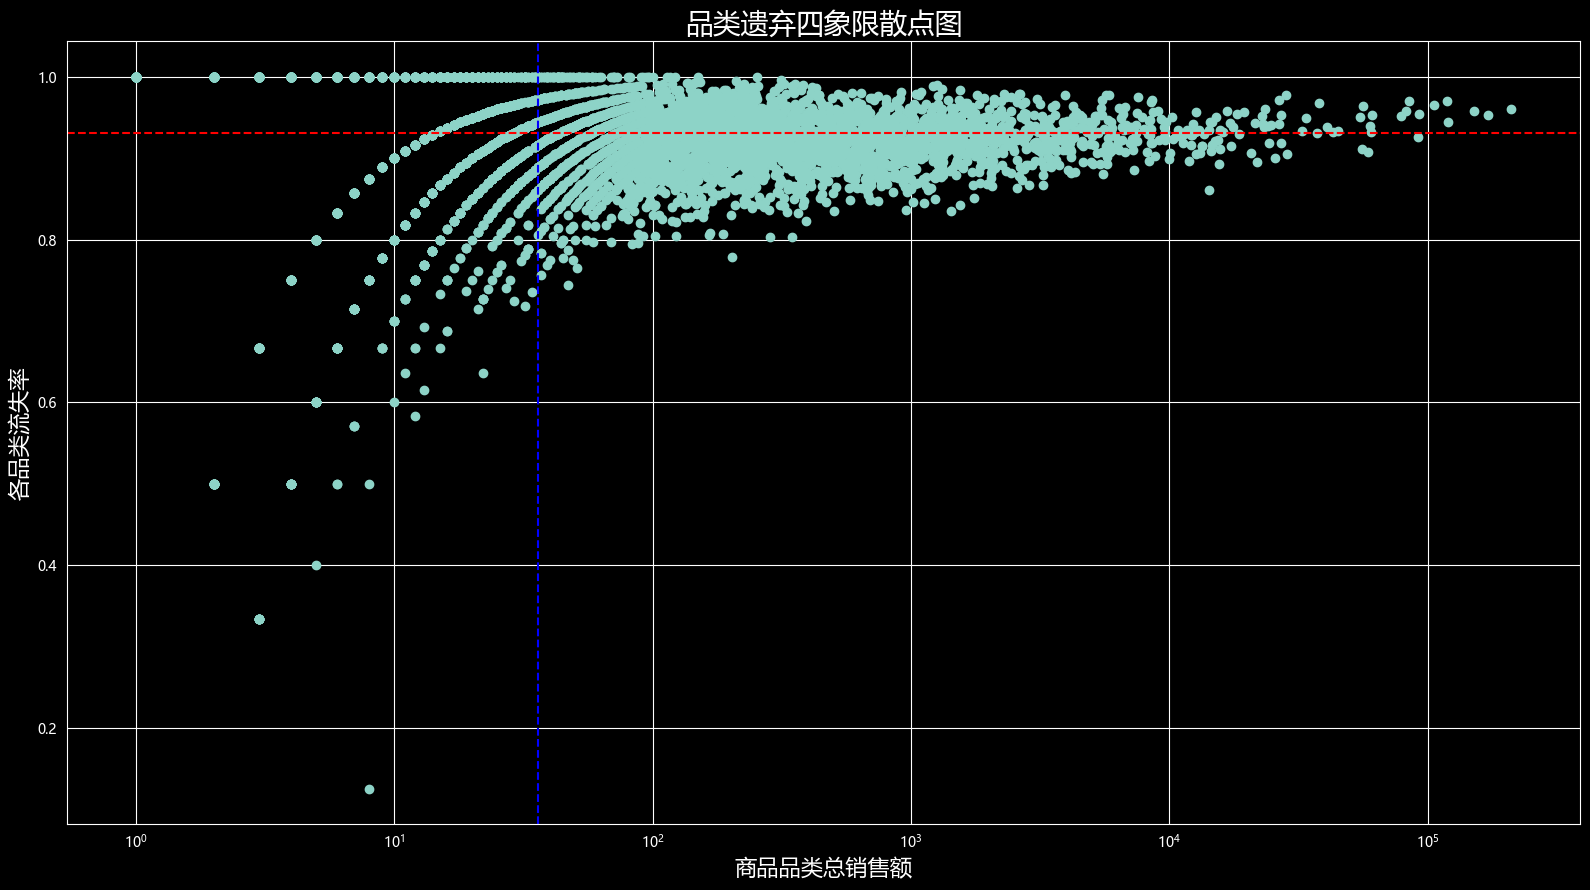

In [5]:



import matplotlib.pyplot as plt
import numpy as np
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']   # 列表形式，写全名
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.unicode_minus'] = False
plt.figure(figsize=(16,9))
plt.scatter(df_rate['total_cnt'],df_rate['rate'])
plt.xlabel('商品品类总销售额',fontsize=16)
plt.ylabel('各品类流失率',fontsize=16)
plt.title('品类遗弃四象限散点图',fontsize=20)
plt.axhline(df_rate['rate'].mean(),color='red',linestyle='--')
plt.axvline(df_rate['total_cnt'].median(),color='blue',linestyle='--')
plt.xscale('log')
plt.tight_layout()
plt.show()


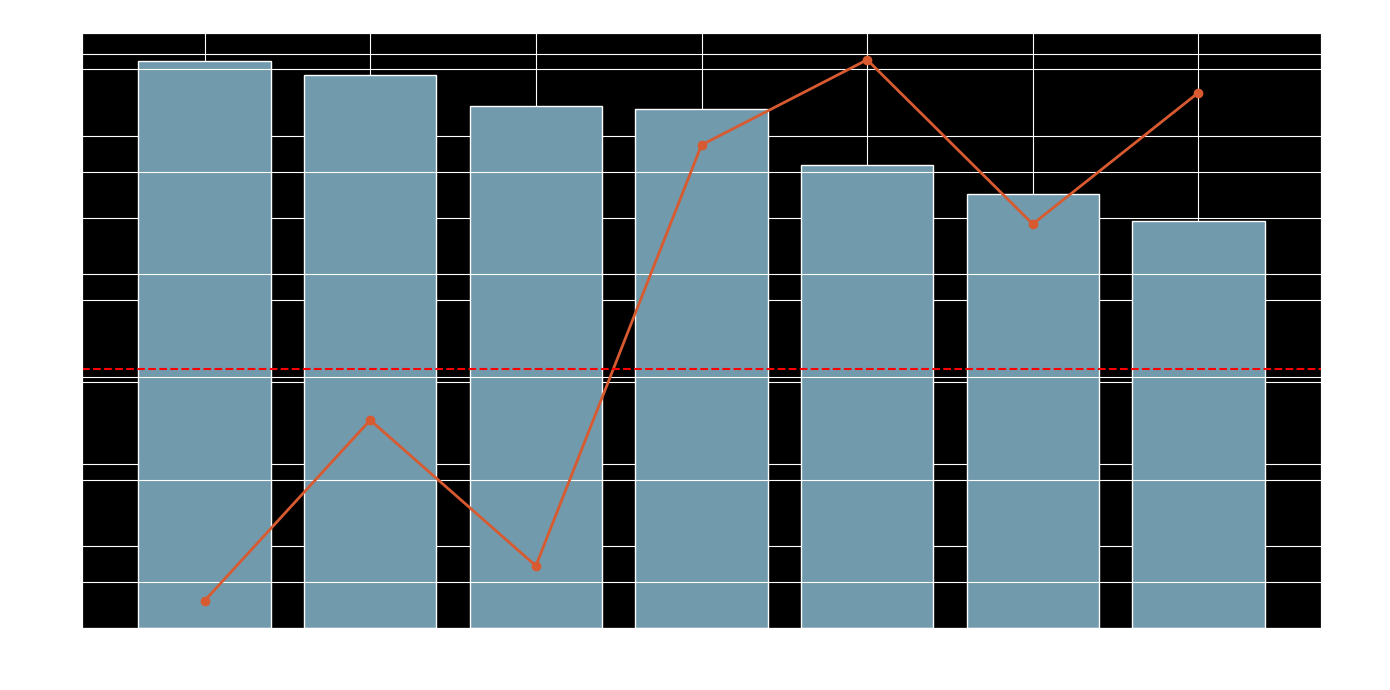

In [6]:
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']   # 列表形式，写全名
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.unicode_minus'] = False
sales = df_buy.groupby('product_cat_id')['user_id'] .count().rename('buy_cnt').reset_index()

combo = df_rate.merge(sales, on='product_cat_id')
top7 = combo.sort_values('buy_cnt', ascending=False).head(7)

fig, ax1 = plt.subplots(figsize=(14, 7), facecolor='white')
ax1.bar(top7['product_cat_id'].astype(str), top7['buy_cnt'],
        color='#719AAC', label='购买人次')
ax1.set_ylabel('购买人次')

ax2 = ax1.twinx()                                          # 双轴：右轴放遗弃率
ax2.plot(top7['product_cat_id'].astype(str), top7['rate'],
         color='#D85A30', marker='o', linewidth=2, label='遗弃率')
ax2.axhline(df_rate['rate'].mean(), color='red', linestyle='--', label='全站平均遗弃率')
ax2.set_ylabel('遗弃率')

ax1.set_title('销量 Top7 品类 × 购物车遗弃率')
fig.autofmt_xdate()                                        # 品类ID标签斜排
plt.tight_layout()
plt.show()


      product_cat_id     cnt  total_cnt    rate
6893         4756105  201949     210157  0.9609
6035         4145813  162667     170764  0.9526
1425          982926  144123     150491  0.9577
3398         2355072  115431     118965  0.9703
6964         4801426  112662     119235  0.9449
5251         3607361  102242     105956  0.9649
1887         1320293   88371      92568  0.9547
3954         2735466   84458      91230  0.9258
3619         2520377   82285      84768  0.9707
3548         2465336   79167      82635  0.9580


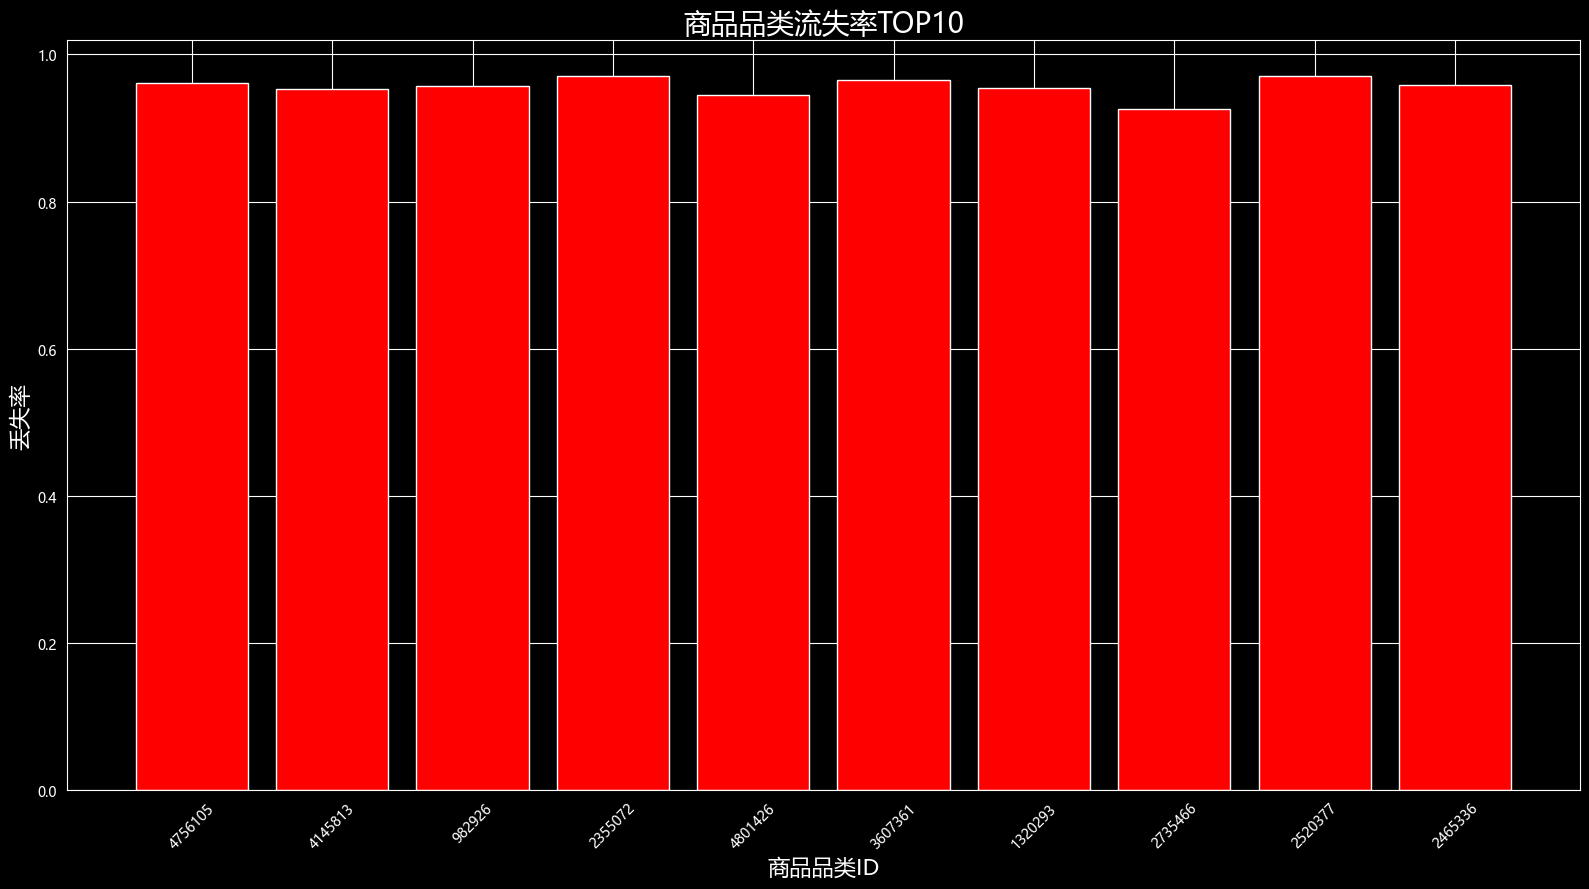

In [7]:
df2=df_rate.sort_values(by=['cnt','rate'], ascending=[False,False]).head(10)
print(df2)
plt.figure(figsize=(16,9))
plt.bar(df2['product_cat_id'].astype(str),df2['rate'],color='red')
plt.title("商品品类流失率TOP10",fontsize=20)
plt.xlabel("商品品类ID",fontsize=16)
plt.ylabel("丢失率",fontsize=16)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
